In [ ]:
import numpy as np
import pandas as pd
import geopandas as gpd
from matplotlib import pyplot as plt
from matplotlib.colors import BoundaryNorm
from matplotlib.cm import ScalarMappable
import matplotlib.ticker as mticker
from matplotlib.lines import Line2D
from pathlib import Path
from tqdm import tqdm

In [ ]:
ROOT = Path.cwd().parent
DATA = ROOT    / "data"
RESULTS = ROOT / "results"
FIGURES = ROOT / "figures"
MFA_RESULTS = Path(r"F:\aggregates-mining-biodiversity\results\material-flows")


In [ ]:
import sys
sys.path.insert(0, str(ROOT / '1-IMAGINE-Concrete'))
from IMAGINE_Concrete import fit_logistic_with_constraints


In [ ]:
df_cement_production = pd.read_csv(DATA / 'production-142.csv', index_col=0)
economies_142 = df_cement_production.columns.tolist()

In [ ]:
stock_growth_of_economies_142_SSP1 = pd.read_excel(RESULTS / 'future-stock-growth.xlsx', sheet_name='SSP1', index_col=0)
stock_growth_of_economies_142_SSP2 = pd.read_excel(RESULTS / 'future-stock-growth.xlsx', sheet_name='SSP2', index_col=0)
stock_growth_of_economies_142_SSP3 = pd.read_excel(RESULTS / 'future-stock-growth.xlsx', sheet_name='SSP3', index_col=0)
stock_growth_of_economies_142_SSP4 = pd.read_excel(RESULTS / 'future-stock-growth.xlsx', sheet_name='SSP4', index_col=0)
stock_growth_of_economies_142_SSP5 = pd.read_excel(RESULTS / 'future-stock-growth.xlsx', sheet_name='SSP5', index_col=0)

In [ ]:
mid, end = 2022, 2050

In [ ]:
economy = 'CHN'

In [ ]:
hist_dir = MFA_RESULTS / economy / 'historical'


In [ ]:
S_binder_annual = np.load(hist_dir / 'S_binder_annual.npz')['data']

historical_stock_trajectory = np.median(S_binder_annual, axis=0) / np.median(S_binder_annual, axis=0)[-1]

K_SSP1 = stock_growth_of_economies_142_SSP1.loc[end, economy]
K_SSP2 = stock_growth_of_economies_142_SSP2.loc[end, economy]
K_SSP3 = stock_growth_of_economies_142_SSP3.loc[end, economy]
K_SSP4 = stock_growth_of_economies_142_SSP4.loc[end, economy]
K_SSP5 = stock_growth_of_economies_142_SSP5.loc[end, economy]

fitted_stock_trajectory_SSP1 = fit_logistic_with_constraints(historical_stock_trajectory, K_SSP1)
fitted_stock_trajectory_SSP2 = fit_logistic_with_constraints(historical_stock_trajectory, K_SSP2)
fitted_stock_trajectory_SSP3 = fit_logistic_with_constraints(historical_stock_trajectory, K_SSP3)
fitted_stock_trajectory_SSP4 = fit_logistic_with_constraints(historical_stock_trajectory, K_SSP4)
fitted_stock_trajectory_SSP5 = fit_logistic_with_constraints(historical_stock_trajectory, K_SSP5)

In [ ]:
def transform_year(y, mid=2022, start=1931, end=2050):
    y = np.asarray(y, dtype=float)
    out = np.where(
        y <= mid,
        (y - start) / (mid - start) * 0.5,
        0.5 + (y - mid) / (end - mid) * 0.5
    )
    return out

In [ ]:
all_stock_trajectories = {}

for economy in tqdm(economies_142):
    S_binder_annual = np.load(MFA_RESULTS / economy / "historical/S_binder_annual.npz")["data"]
    K_SSP1 = stock_growth_of_economies_142_SSP1.loc[end, economy]
    K_SSP2 = stock_growth_of_economies_142_SSP2.loc[end, economy]
    K_SSP3 = stock_growth_of_economies_142_SSP3.loc[end, economy]
    K_SSP4 = stock_growth_of_economies_142_SSP4.loc[end, economy]
    K_SSP5 = stock_growth_of_economies_142_SSP5.loc[end, economy]

    historical_stock_trajectory = np.median(S_binder_annual, axis=0) / np.median(S_binder_annual, axis=0)[-1]

    fitted_stock_trajectory_SSP1 = fit_logistic_with_constraints(historical_stock_trajectory, K_SSP1)
    fitted_stock_trajectory_SSP2 = fit_logistic_with_constraints(historical_stock_trajectory, K_SSP2)
    fitted_stock_trajectory_SSP3 = fit_logistic_with_constraints(historical_stock_trajectory, K_SSP3)
    fitted_stock_trajectory_SSP4 = fit_logistic_with_constraints(historical_stock_trajectory, K_SSP4)
    fitted_stock_trajectory_SSP5 = fit_logistic_with_constraints(historical_stock_trajectory, K_SSP5)

    all_stock_trajectories[economy] = {
        'historical': historical_stock_trajectory,
        'SSP1': fitted_stock_trajectory_SSP1.loc[mid:].values,
        'SSP2': fitted_stock_trajectory_SSP2.loc[mid:].values,
        'SSP3': fitted_stock_trajectory_SSP3.loc[mid:].values,
        'SSP4': fitted_stock_trajectory_SSP4.loc[mid:].values,
        'SSP5': fitted_stock_trajectory_SSP5.loc[mid:].values,
    }

In [ ]:
growth_2050 = pd.DataFrame({
    economy: {
        'SSP1': traj['SSP1'][-1],
        'SSP2': traj['SSP2'][-1],
        'SSP3': traj['SSP3'][-1],
        'SSP4': traj['SSP4'][-1],
        'SSP5': traj['SSP5'][-1],
    }
    for economy, traj in all_stock_trajectories.items()
}).T

# 用 5 个 SSP 的最大值作为分组依据（覆盖最高增长情景，避免压缩）
growth_metric = growth_2050.max(axis=1)

In [ ]:
economies_sorted = growth_metric.sort_values(ascending=False).index.tolist()

In [ ]:
def nice_axis(ymax):
    nice_steps = [0.5, 1, 2, 5, 10, 15]
    raw_step = ymax / 4
    step = next(s for s in nice_steps if s >= raw_step)
    ymax_nice = np.ceil(ymax / step) * step
    ymax_nice = np.maximum(1.5, ymax_nice)
    return ymax_nice, step

In [ ]:
ssp_colors = {
    'SSP1': '#00a651',  # 鲜绿
    # 'SSP2': '#2e3192',  # 深蓝
    'SSP2': 'blue',  # 深蓝
    'SSP3': '#ed1c24',  # 鲜红
    'SSP4': '#f7941d',  # 橙
    'SSP5': '#92278f',  # 品紫
}

In [ ]:
ncols, nrows = 5, 6
per_fig = ncols * nrows
n_figs = int(np.ceil(len(economies_sorted) / per_fig))

hist_years = np.linspace(1931, 2022, 92)
fut_years = np.linspace(2022, 2050, 29)
hist_x = transform_year(hist_years)
proj_x = transform_year(fut_years)

plt.rcParams['font.family'] = 'Arial'

for fig_idx in range(n_figs):
    chunk = economies_sorted[fig_idx*per_fig : (fig_idx+1)*per_fig]
    
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols*1.8, nrows*1.5),
                             sharey='row', sharex=True, constrained_layout=True)
    axes = axes.flatten()
    
    for i, economy in enumerate(chunk):
        ax = axes[i]

        ax.plot(hist_x, all_stock_trajectories[economy]['historical'], color='grey', lw=1.5)
        for ssp in ['SSP1', 'SSP2', 'SSP3', 'SSP4', 'SSP5']:
            ax.plot(proj_x, all_stock_trajectories[economy][ssp],
                    color=ssp_colors[ssp], lw=1.5 if ssp != 'SSP2' else 3.0, ls='--')

        ax.set_xlim([0, 1])
        ax.set_xticks([0, 0.5, 1])
        ax.set_xticklabels([1931, 2022, 2050])
        ax.grid(True, ls=':', alpha=0.5)
        ax.set_title(economy)

    for row in range(nrows):
        row_axes = axes[row*ncols:(row+1)*ncols]
        visible = [a for a in row_axes if a.get_visible() and a.lines]
        if not visible:
            continue
        ymax = max(max(line.get_ydata().max() for line in a.lines) for a in visible)
        ymax_nice, step = nice_axis(ymax)
        visible[0].set_ylim(0, ymax_nice)
        visible[0].yaxis.set_major_locator(mticker.MultipleLocator(step))

    for j in range(len(chunk), len(axes)):
        axes[j].set_visible(False)
    
    for col in range(ncols):
        col_axes = [axes[row*ncols + col] for row in range(nrows)]
        for ax in reversed(col_axes):
            if ax.get_visible():
                ax.tick_params(labelbottom=True)
                ax.set_xticks([0, 0.25, 0.5, 0.75, 1])
                ax.set_xticklabels([1931, '', 2022, '', 2050])
                break
    
    legend_handles = [Line2D([0], [0], color='grey', lw=1.5, label='Historical')] + [
        Line2D([0], [0], color=c, lw=1.5 if ssp != 'SSP2' else 2.0, ls='--', label=ssp)
        for ssp, c in ssp_colors.items()
    ]
    fig.legend(handles=legend_handles, loc='upper center', ncol=6,
            bbox_to_anchor=(0.5, -0.01 if fig_idx != 4 else 0.13), frameon=False, fontsize=10)

    fig.supylabel('Construction aggregate stock in use (2022 = 1.0)', fontsize=10)

    plt.show()

    fig.savefig(FIGURES / f'Supplementary-Figure-7-part{fig_idx+1}.jpg', dpi=600, bbox_inches='tight')

In [ ]:
ncols, nrows = 5, 6
per_fig = ncols * nrows
n_figs = int(np.ceil(len(economies_sorted) / per_fig))

hist_years = np.linspace(1931, 2022, 92)
fut_years = np.linspace(2022, 2050, 29)
hist_x = transform_year(hist_years)
proj_x = transform_year(fut_years)

plt.rcParams['font.family'] = 'Arial'

for fig_idx in range(n_figs):
    chunk = economies_sorted[fig_idx*per_fig : (fig_idx+1)*per_fig]
    
    fig, axes = plt.subplots(nrows, ncols, figsize=(ncols*1.8, nrows*1.5),
                             sharey='row', sharex=True, constrained_layout=True)
    axes = axes.flatten()
    
    for i, economy in enumerate(chunk):
        ax = axes[i]

        ax.plot(hist_x, all_stock_trajectories[economy]['historical'], color='grey', lw=1.5)
        for ssp in ['SSP1', 'SSP2', 'SSP3', 'SSP4', 'SSP5']:
            ax.plot(proj_x, all_stock_trajectories[economy][ssp],
                    color=ssp_colors[ssp], lw=1.5 if ssp != 'SSP2' else 3.0, ls='--')

        ax.set_xlim([0, 1])
        ax.set_xticks([0, 0.5, 1])
        ax.set_xticklabels([1931, 2022, 2050])
        ax.grid(True, ls=':', alpha=0.5)
        ax.set_title(economy)

    for row in range(nrows):
        row_axes = axes[row*ncols:(row+1)*ncols]
        visible = [a for a in row_axes if a.get_visible() and a.lines]
        if not visible:
            continue
        ymax = max(max(line.get_ydata().max() for line in a.lines) for a in visible)
        ymax_nice, step = nice_axis(ymax)
        visible[0].set_ylim(0, ymax_nice)
        visible[0].yaxis.set_major_locator(mticker.MultipleLocator(step))

    for j in range(len(chunk), len(axes)):
        axes[j].set_visible(False)
    
    for col in range(ncols):
        col_axes = [axes[row*ncols + col] for row in range(nrows)]
        for ax in reversed(col_axes):
            if ax.get_visible():
                ax.tick_params(labelbottom=True)
                ax.set_xticks([0, 0.25, 0.5, 0.75, 1])
                ax.set_xticklabels([1931, '', 2022, '', 2050])
                break
    
    legend_handles = [Line2D([0], [0], color='grey', lw=1.5, label='Historical')] + [
        Line2D([0], [0], color=c, lw=1.5 if ssp != 'SSP2' else 2.0, ls='--', label=ssp)
        for ssp, c in ssp_colors.items()
    ]
    fig.legend(handles=legend_handles, loc='upper center', ncol=6,
            bbox_to_anchor=(0.5, -0.01 if fig_idx != 4 else 0.13), frameon=False, fontsize=10)

    fig.supylabel('Construction aggregate stock in use (2022 = 1.0)', fontsize=10)

    plt.show()

    # fig.savefig(FIGURES / f'Supplementary-Figure-7-part{fig_idx+1}.jpg', dpi=600, bbox_inches='tight')

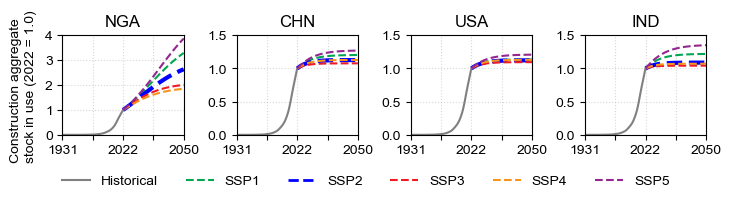

In [144]:
selected = ['NGA', 'CHN', 'USA', 'IND', ]  # 改成你想要的

hist_years = np.linspace(1931, 2022, 92)
fut_years = np.linspace(2022, 2050, 29)
hist_x = transform_year(hist_years)
proj_x = transform_year(fut_years)

plt.rcParams['font.family'] = 'Arial'

fig, axes = plt.subplots(1, 4, figsize=(4*1.8, 1.5),
                         sharex=True, constrained_layout=True)

for ax, economy in zip(axes, selected):
    ax.plot(hist_x, all_stock_trajectories[economy]['historical'], color='grey', lw=1.5)
    for ssp in ['SSP1', 'SSP2', 'SSP3', 'SSP4', 'SSP5']:
        ax.plot(proj_x, all_stock_trajectories[economy][ssp],
                color=ssp_colors[ssp], lw=3.0 if ssp == 'SSP2' else 1.5, ls='--')

    ax.set_xlim([0, 1])
    ax.set_xticks([0, 0.25, 0.5, 0.75, 1])
    ax.set_xticklabels([1931, '', 2022, '', 2050])
    ax.grid(True, ls=':', alpha=0.5)
    ax.set_title(economy)

    # 每个子图独立 y 轴
    ymax = max(line.get_ydata().max() for line in ax.lines)
    ymax_nice, step = nice_axis(ymax)
    ax.set_ylim(0, ymax_nice)
    ax.yaxis.set_major_locator(mticker.MultipleLocator(step))

legend_handles = [Line2D([0], [0], color='grey', lw=1.5, label='Historical')] + [
    Line2D([0], [0], color=c, lw=2.0 if ssp == 'SSP2' else 1.5, ls='--', label=ssp)
    for ssp, c in ssp_colors.items()
]
fig.legend(handles=legend_handles, loc='upper center', ncol=6,
           bbox_to_anchor=(0.5, -0.01), frameon=False, fontsize=10)

fig.supylabel('Construction aggregate\nstock in use (2022 = 1.0)', fontsize=10)

plt.show()
fig.savefig(FIGURES / 'selected-stock-trajectory.jpg', dpi=600, bbox_inches='tight')